In [ ]:
# Core
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit

# imbalance
from imblearn.over_sampling import SMOTE

# models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score

import xgboost as xgb
import lightgbm as lgb

%pip install catboost
from catboost import CatBoostClassifier

# warning ignore
import warnings
warnings.filterwarnings("ignore")

Could not find platform independent libraries <prefix>

[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
data = pd.read_csv("Application_Data.csv")

print(data.shape)
print(data.columns)
print(data['Status'].value_counts())

(25128, 21)
Index(['Applicant_ID', 'Applicant_Gender', 'Owned_Car', 'Owned_Realty',
       'Total_Children', 'Total_Income', 'Income_Type', 'Education_Type',
       'Family_Status', 'Housing_Type', 'Owned_Mobile_Phone',
       'Owned_Work_Phone', 'Owned_Phone', 'Owned_Email', 'Job_Title',
       'Total_Family_Members', 'Applicant_Age', 'Years_of_Working',
       'Total_Bad_Debt', 'Total_Good_Debt', 'Status'],
      dtype='str')
Status
1    25007
0      121
Name: count, dtype: int64


In [8]:
# Create 3-class credit risk classification based on composite risk indicators
# Use income, debt, and default status to create risk tiers

# Normalize features for risk calculation
total_income_norm = (data['Total_Income'] - data['Total_Income'].min()) / (data['Total_Income'].max() - data['Total_Income'].min())
bad_debt_norm = (data['Total_Bad_Debt'] - data['Total_Bad_Debt'].min()) / (data['Total_Bad_Debt'].max() - data['Total_Bad_Debt'].min() + 1)

# Calculate composite risk score
risk_score = (
    bad_debt_norm * 0.5 +  # High weight on bad debt
    (1 - total_income_norm) * 0.3 +  # High weight on low income
    data['Status'].astype(float) * 0.2  # Default history
)

# Create 3 balanced classes using quantiles
data['Status'] = pd.qcut(risk_score, q=3, labels=[0, 1, 2], duplicates='drop')
data['Status'] = data['Status'].astype(int)

print("Multiclass Credit Risk Distribution (3 classes):")
print(data['Status'].value_counts().sort_index())
print("\nClass proportions:")
print(data['Status'].value_counts(normalize=True).sort_index())

Multiclass Credit Risk Distribution (3 classes):
Status
0    9562
1    7197
2    8369
Name: count, dtype: int64

Class proportions:
Status
0    0.380532
1    0.286414
2    0.333055
Name: proportion, dtype: float64


In [10]:
data = data.ffill().bfill()  # Forward fill, then back fill

In [11]:
le = LabelEncoder()

for col in data.select_dtypes(include='object').columns:
    data[col] = le.fit_transform(data[col])

In [12]:
X = data.drop(columns=['Applicant_ID','Status'])
y = data['Status']

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [34]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_split=15,
    min_samples_leaf=8,
    class_weight='balanced_subsample',
    random_state=42,
    max_features='sqrt'
)

et = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_split=15,
    min_samples_leaf=8,
    class_weight='balanced_subsample',
    random_state=42,
    max_features='sqrt'
)

xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=1.5,
    reg_lambda=1.5,
    scale_pos_weight=1.5,
    eval_metric='mlogloss',
    random_state=42
)

lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.08,
    max_depth=7,
    num_leaves=31,
    reg_alpha=0.5,
    reg_lambda=0.5,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=5,
    is_unbalance=True,
    verbose=-1,
    random_state=42
)

cat_model = CatBoostClassifier(
    iterations=150,
    depth=5,
    learning_rate=0.1,
    l2_leaf_reg=5,
    auto_class_weights='Balanced',
    verbose=0,
    random_state=42
)

In [35]:
base_models = [
    ('rf', rf),
    ('et', et),
    ('xgb', xgb_model),
    ('lgb', lgb_model),
    ('cat', cat_model)
]

meta_model = LogisticRegression(max_iter=2000, C=0.5, class_weight='balanced', random_state=42)

stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5,
    n_jobs=-1
)

stack_model.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('rf', ...), ('et', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...ndom_state=42)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary ` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_split min_samples_split: int or float, default=2The minimum number of sample

In [36]:
y_pred = stack_model.predict(X_test)

In [38]:
from sklearn.utils.class_weight import compute_sample_weight

# Compute sample weights for balanced training
sample_weights = compute_sample_weight('balanced', y_train)

models = {
    "Random Forest": rf,
    "Extra Trees": et,
    "XGBoost": xgb_model,
    "LightGBM": lgb_model,
    "CatBoost": cat_model,
    "Hybrid Stacking": stack_model
}

results = []

for name, model in models.items():
    if name == "Hybrid Stacking":
        # Stacking classifier handles its own fitting
        model.fit(X_train, y_train)
    else:
        # Use sample weights for all base models
        model.fit(X_train, y_train, sample_weight=sample_weights)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

    results.append([name, accuracy, precision, recall, f1])

    print("\n", name)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)


 Random Forest
Accuracy: 0.6848388380421807
Precision: 0.7450797383513952
Recall: 0.6839989252680376
F1 Score: 0.5884388648386906

 Extra Trees
Accuracy: 0.5827695980899323
Precision: 0.6085865973590888
Recall: 0.5968395423622496
F1 Score: 0.5627011141507964

 XGBoost
Accuracy: 0.7518901711102268
Precision: 0.7674643588404301
Recall: 0.7510409351358357
F1 Score: 0.7149391781616433

 LightGBM
Accuracy: 0.8292877039395146
Precision: 0.8396232383172914
Recall: 0.828788872318091
F1 Score: 0.8155667911473143

 CatBoost
Accuracy: 0.6872264226024671
Precision: 0.6907864257158612
Recall: 0.6856157854483196
F1 Score: 0.6068279356158786

 Hybrid Stacking
Accuracy: 0.8561480302427378
Precision: 0.8531467247535315
Recall: 0.8560233160924501
F1 Score: 0.8514106191215115


In [39]:
results_df = pd.DataFrame(
    results,
    columns=["Model","Accuracy","Precision","Recall","F1 Score"]
)

results_df = results_df.sort_values(by="F1 Score", ascending=False)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
5,Hybrid Stacking,0.856148,0.853147,0.856023,0.851411
3,LightGBM,0.829288,0.839623,0.828789,0.815567
2,XGBoost,0.751890,0.767464,0.751041,0.714939
4,CatBoost,0.687226,0.690786,0.685616,0.606828
0,Random Forest,0.684839,0.745080,0.683999,0.588439
1,Extra Trees,0.582770,0.608587,0.596840,0.562701


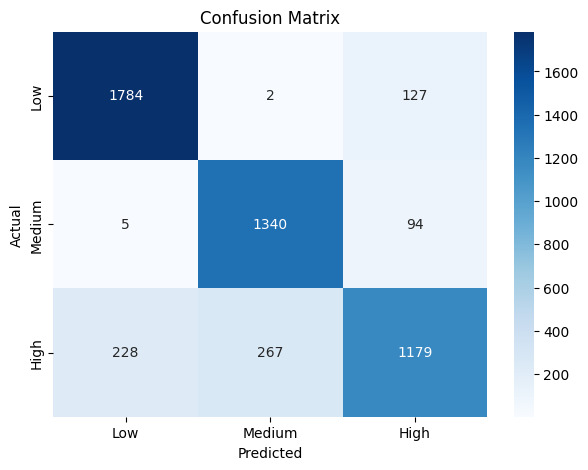

In [40]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7,5))

class_names = ['Low', 'Medium', 'High']
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

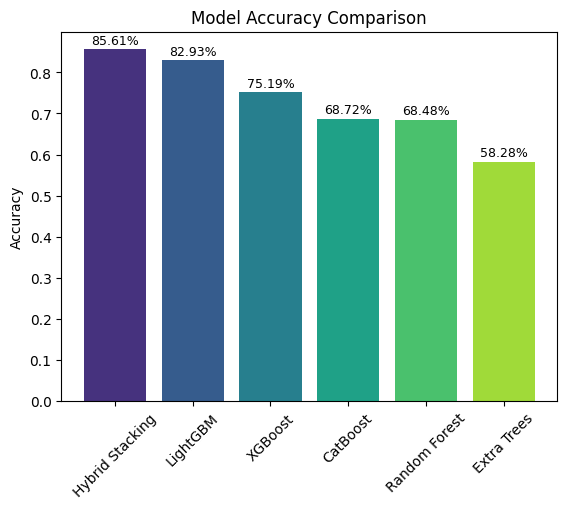

In [41]:
plt.figure()
colors = sns.color_palette('viridis', len(results_df["Model"]))
bars = plt.bar(results_df["Model"], results_df["Accuracy"], color=colors)
plt.xticks(rotation=45)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f'{yval*100:.2f}%', ha='center', va='bottom', fontsize=9)

plt.show()

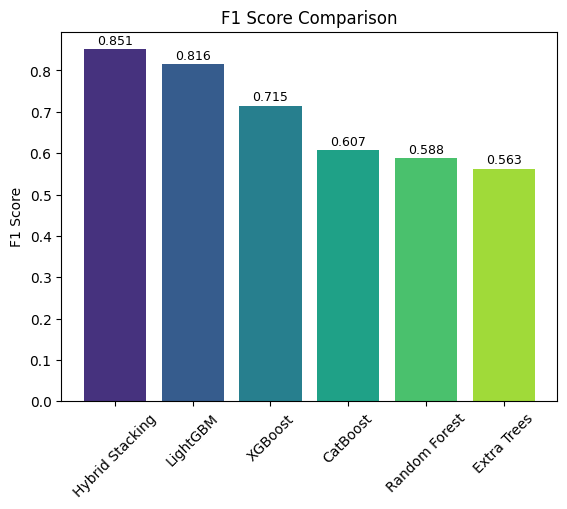

In [43]:
plt.figure()
colors = sns.color_palette('viridis', len(results_df["Model"]))
bars = plt.bar(results_df["Model"], results_df["F1 Score"], color=colors)
plt.xticks(rotation=45)
plt.title("F1 Score Comparison")
plt.ylabel("F1 Score")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f'{yval:.3f}', ha='center', va='bottom', fontsize=9)
plt.show()

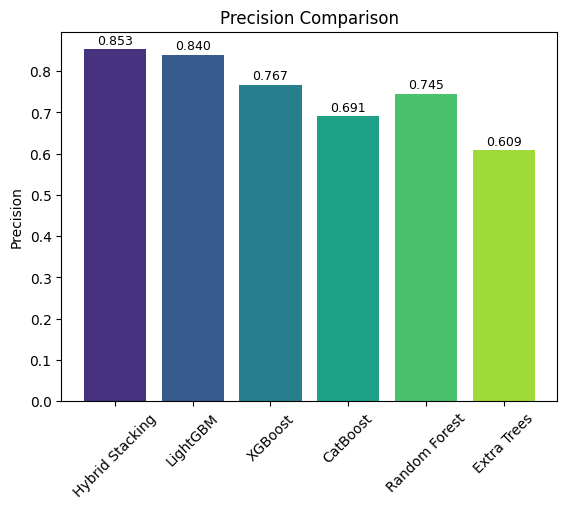

In [44]:
plt.figure()
colors = sns.color_palette('viridis', len(results_df["Model"]))
bars = plt.bar(results_df["Model"], results_df["Precision"], color=colors)

plt.xticks(rotation=45)
plt.title("Precision Comparison")
plt.ylabel("Precision")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f'{yval:.3f}', ha='center', va='bottom', fontsize=9)

plt.show()

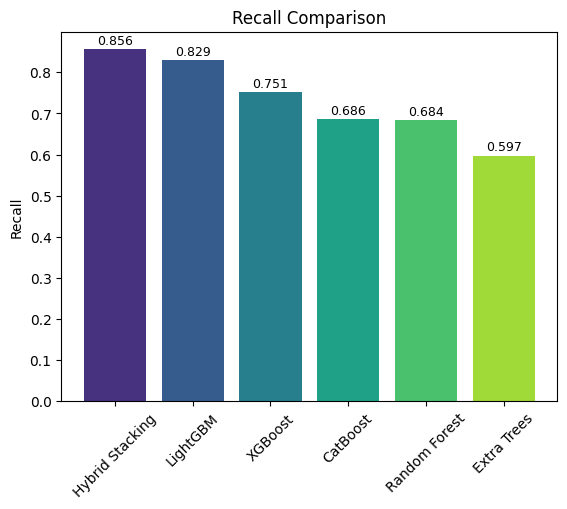

In [45]:
plt.figure()
colors = sns.color_palette('viridis', len(results_df["Model"]))
bars = plt.bar(results_df["Model"], results_df["Recall"], color=colors)
plt.xticks(rotation=45)
plt.title("Recall Comparison")
plt.ylabel("Recall")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.005, f'{yval:.3f}', ha='center', va='bottom', fontsize=9)

plt.show()

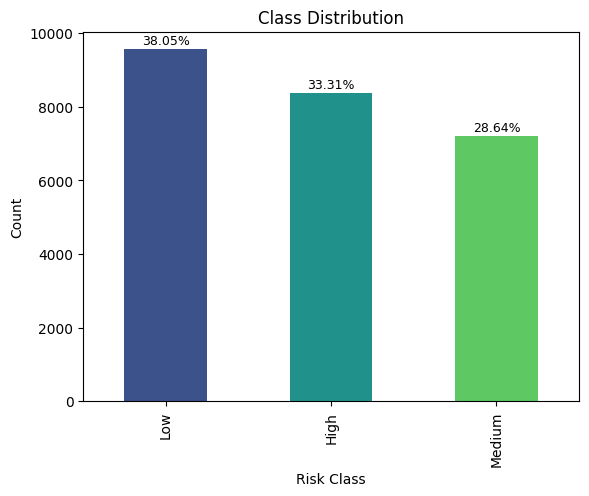

In [46]:
plt.figure()

class_counts = pd.Series(y).value_counts()
total_count = class_counts.sum()
class_labels = {0: 'Low', 1: 'Medium', 2: 'High'}
class_counts.index = class_counts.index.map(class_labels)
colors = sns.color_palette('viridis', len(class_counts))
bars = class_counts.plot(kind='bar', color=colors)

plt.title("Class Distribution")
plt.xlabel("Risk Class")
plt.ylabel("Count")
for i, bar in enumerate(bars.patches):
    yval = bar.get_height()
    percentage = (yval / total_count) * 100
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{percentage:.2f}%', ha='center', va='bottom', fontsize=9)

plt.show()

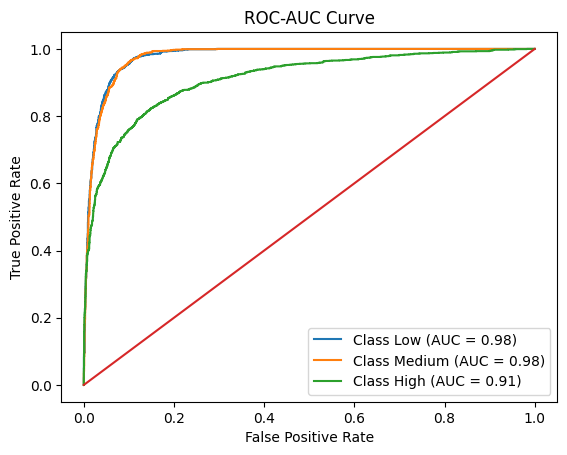

In [47]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_prob = stack_model.predict_proba(X_test)
classes = np.unique(y_test)
y_test_bin = label_binarize(y_test, classes=classes)
plt.figure()
class_labels_roc = {0: 'Low', 1: 'Medium', 2: 'High'}

for i in range(len(classes)):

    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])

    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'Class {class_labels_roc[classes[i]]} (AUC = {roc_auc:.2f})')

plt.plot([0,1],[0,1])

plt.title("ROC-AUC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.show()